In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [12]:
train_dir='../data/pictures_imagein/Intel_Image_Classification/data_split/train'
test_dir='../data/pictures_imagein/Intel_Image_Classification/data_split/test'
val_dir='../data/pictures_imagein/Intel_Image_Classification/data_split/validation'

img_size=(224,224)
batch_size=32
seed=42

train_ds=tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    seed=seed,
    shuffle=True
)

val_ds=tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=img_size,
    batch_size=batch_size,
    seed=seed,
    shuffle=False
)

test_ds=tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=img_size,
    batch_size=batch_size,
    seed=seed,
    shuffle=True
)

class_names = train_ds.class_names

Found 11898 files belonging to 6 classes.
Found 4333 files belonging to 6 classes.
Found 769 files belonging to 6 classes.


In [13]:
for images,labels in train_ds.take(1):
    print(images)
    print(labels)
    print(images.shape)
    print("minimum:", tf.reduce_min(images).numpy())
    print("maximum:", tf.reduce_max(images).numpy())

tf.Tensor(
[[[[0.00000000e+00 1.00000000e+00 0.00000000e+00]
   [0.00000000e+00 1.00000000e+00 0.00000000e+00]
   [0.00000000e+00 8.25892806e-01 0.00000000e+00]
   ...
   [1.74102783e-01 1.74102783e-01 1.82589722e+00]
   [0.00000000e+00 0.00000000e+00 2.00000000e+00]
   [0.00000000e+00 0.00000000e+00 2.00000000e+00]]

  [[0.00000000e+00 1.00000000e+00 0.00000000e+00]
   [0.00000000e+00 1.00000000e+00 0.00000000e+00]
   [0.00000000e+00 8.25892806e-01 0.00000000e+00]
   ...
   [8.62741470e-02 8.62741470e-02 1.73806858e+00]
   [0.00000000e+00 0.00000000e+00 2.00000000e+00]
   [0.00000000e+00 0.00000000e+00 2.00000000e+00]]

  [[0.00000000e+00 8.25892806e-01 0.00000000e+00]
   [0.00000000e+00 8.25892806e-01 0.00000000e+00]
   [0.00000000e+00 6.82098925e-01 0.00000000e+00]
   ...
   [3.03125475e-02 3.03125475e-02 1.68210697e+00]
   [0.00000000e+00 0.00000000e+00 2.00000000e+00]
   [0.00000000e+00 0.00000000e+00 2.00000000e+00]]

  ...

  [[3.48205566e-01 3.48205566e-01 3.48205566e-01]
   [1

In [14]:
normalization_layer=tf.keras.layers.Rescaling(1./255)    
train_ds=train_ds.map(
        lambda images,labels: (normalization_layer(images),labels)
)
test_ds=test_ds.map(
        lambda images,labels: (normalization_layer(images),labels)
)
val_ds=val_ds.map(
        lambda images,labels: (normalization_layer(images),labels)
)



In [15]:
for images, labels in train_ds.take(1):
    print("Normalized minimum:", tf.reduce_min(images).numpy())
    print("Normalized maximum:", tf.reduce_max(images).numpy())
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Normalized minimum: 0.0
Normalized maximum: 1.0
Images shape: (32, 224, 224, 3)
Labels shape: (32,)


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

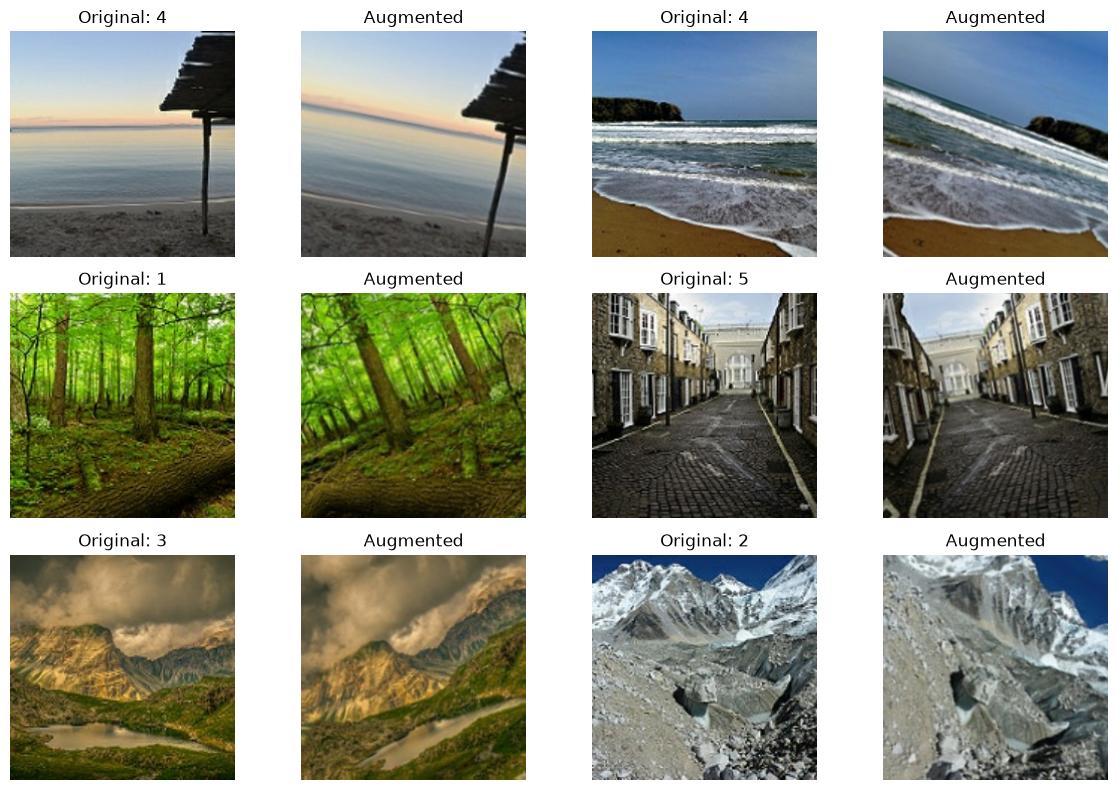

In [17]:


for images, labels in train_ds.take(1):
    plt.figure(figsize=(12, 8))

    for i in range(6):
        plt.subplot(3, 4, 2 * i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f"Original: {labels[i].numpy()}")
        plt.axis("off")

        augmented = data_augmentation(
            tf.expand_dims(images[i], axis=0),
            training=True
        )[0]

        plt.subplot(3, 4, 2 * i + 2)
        plt.imshow(tf.clip_by_value(augmented, 0, 1).numpy())
        plt.title("Augmented")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [18]:

num_classes = len(class_names)

model = tf.keras.Sequential([
   
    tf.keras.layers.Input(shape=(224, 224, 3)),

    
    data_augmentation,

   
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),


    tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

   
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    
    tf.keras.layers.GlobalAveragePooling2D(),

    
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])


In [19]:
print(tf.config.list_physical_devices())

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,       # divise le learning rate par 2
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint('best_model.keras', save_best_only=True)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

In [ ]:
acc, val_acc = history.history['accuracy'], history.history['val_accuracy']
loss, val_loss = history.history['loss'], history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Train')
plt.plot(epochs_range, val_acc, label='Validation')
plt.title('Accuracy')
plt.xlabel('Époque'); plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Train')
plt.plot(epochs_range, val_loss, label='Validation')
plt.title('Loss')
plt.xlabel('Époque'); plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()